# Part 0 — verify the monthly equal-weight benchmark

This notebook earns one dependable reference series before any ML work. The
assignment explicitly asks for monthly rebalancing and gives forward one-month
returns for each stock. We use every stock available at each snapshot, put equal
capital into each, and earn the following month's supplied return.

The result is the equally weighted **available universe** in these CSVs. It is
not a capitalization-weighted market index. The professor's reference value is
not supplied, so independent accounting checks are more useful than guessing a
hidden trick.

The benchmark rule is fixed without fitting or choosing parameters. We report
training and test periods separately. The earlier test inspection is documented
in `00_readme.md`; nothing here restores an untouched holdout for future models.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display, Markdown

# Locate the shared module without a machine-specific path.
search_roots = [Path.cwd(), *Path.cwd().parents]
FOUNDATION = next(
    candidate
    for base in search_roots
    for candidate in [
        base,
        base / 'part0_data_and_benchmark',
        base / '11_mlfactor_long_only_project_2026' / 'part0_data_and_benchmark',
    ]
    if (candidate / 'pipeline.py').is_file()
)
if str(FOUNDATION) not in sys.path:
    sys.path.insert(0, str(FOUNDATION))
from pipeline import (
    TARGET, FEATURES, FEATURE_INFO, project_root, load_panel, panel_audit,
    return_month, equal_weights, portfolio_returns, performance,
)
ROOT = project_root(FOUNDATION)
OUT = FOUNDATION / 'outputs'
FIGURES = OUT / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_columns', 15)
pd.set_option('display.max_rows', 25)

def save_figure(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES / (name + '.png'), dpi=160, bbox_inches='tight')
    fig.savefig(FIGURES / (name + '.svg'), bbox_inches='tight')
    plt.show()

## 1. Average across stocks, compound across months

For $N_t$ stocks at snapshot $t$, the portfolio return in the following month is

$$r_{p,t+1}=\sum_i w_{i,t}r_{i,t+1}=\frac{1}{N_t}\sum_i r_{i,t+1}.$$

Then the wealth path from \$1 is $W_T=\prod_{m=1}^{T}(1+r_{p,m})$, and its
annualized compound return is $W_T^{12/T}-1$. Every month receives one place in
the time series regardless of how many stocks happened to exist that month.

A stock ID or factor percentile is not a portfolio weight. We do not filter for
stocks that survive to the end, apply another return shift, drop the December
2009 snapshot, or clip extreme supplied returns.

## 2. A two-stock worked example

In January A doubles and B is flat. In February A is flat and B doubles. Start
with \$0.50 in each. After January the portfolio is worth $1.50. Monthly
rebalancing puts \$0.75 in each for February, ending at $2.25. Never rebalancing
instead leaves \$1 in each at the end, totaling $2.00. These are different rules.

In [2]:
toy = pd.DataFrame({
    'date': pd.to_datetime(['2020-12-31'] * 2 + ['2021-01-31'] * 2),
    'stock_id': ['A', 'B', 'A', 'B'],
    TARGET: [1.0, 0.0, 0.0, 1.0],
})
toy_book = portfolio_returns(toy)
display(toy)
display(toy_book[['simple_return', 'log_return', 'wealth', 'turnover_one_way']])
assert np.allclose(toy_book.simple_return, [0.5, 0.5])
assert np.isclose(toy_book.wealth.iloc[-1], 2.25)
wrong_monthly = np.expm1(np.log1p(toy.loc[toy.date.eq(toy.date.min()), TARGET]).mean())
print(f'Correct January simple portfolio return: {toy_book.simple_return.iloc[0]:.2%}')
print(f'Averaging stock log returns and exponentiating gives: {wrong_monthly:.2%}')
print('The latter is not the equal-capital portfolio return.')

,date,stock_id,R1M_Usd
0,2020-12-31,A,1.0
1,2020-12-31,B,0.0
2,2021-01-31,A,0.0
3,2021-01-31,B,1.0


,simple_return,log_return,wealth,turnover_one_way
return_month,,,,
2021-01-31,0.5,0.405465,1.50,NaN
2021-02-28,0.5,0.405465,2.25,0.166667


Correct January simple portfolio return: 50.00%
Averaging stock log returns and exponentiating gives: 41.42%
The latter is not the equal-capital portfolio return.


## 3. Compute the real benchmark and verify it independently

There are three checks: the shared keyed-weight engine, a direct average by
snapshot date, and a separate dollar-allocation calculation. The latter allocates
$1/N_t$ to each stock and sums the ending dollar values for that month.
These checks can detect implementation mistakes, although they share the same
supplied data and timing assumptions.

Training snapshots earn January 2000–December 2009. Test snapshots earn January
2010–December 2018. The test file's December 2009 snapshot must be retained.

In [3]:
panels = {split: load_panel(split, ROOT) for split in ['train', 'test']}
books = {}
for split, panel in panels.items():
    book = portfolio_returns(panel)
    direct = panel.groupby('date')[TARGET].mean()
    direct.index = return_month(direct.index)
    np.testing.assert_allclose(book.simple_return, direct, rtol=1e-12, atol=1e-14)
    dollar_account = []
    for _, rows in panel.groupby('date', sort=True):
        allocation = 1.0 / len(rows)
        ending_dollars = sum(allocation * (1 + stock_return) for stock_return in rows[TARGET])
        dollar_account.append(ending_dollars - 1.0)
    np.testing.assert_allclose(book.simple_return, dollar_account, rtol=1e-11, atol=1e-13)
    # Equivalent compounding via portfolio log returns must give the same wealth.
    np.testing.assert_allclose(np.exp(book.log_return.cumsum()), book.wealth, rtol=1e-12)
    books[split] = book
    book.to_csv(OUT / f'equal_weight_{split}_monthly.csv')
    print(f'{split}: {len(book)} returns, {book.index.min():%Y-%m} through {book.index.max():%Y-%m}; three checks pass.')
assert len(books['train']) == 120
assert len(books['test']) == 108
assert books['test'].index.min() == pd.Timestamp('2010-01-31')
assert books['test'].index.max() == pd.Timestamp('2018-12-31')
display(books['test'].head())

train: 120 returns, 2000-01 through 2009-12; three checks pass.


test: 108 returns, 2010-01 through 2018-12; three checks pass.


,snapshot_date,n_assets,n_held,simple_return,turnover_one_way,log_return,wealth,drawdown
return_month,,,,,,,,
2010-01-31,2009-12-31,1193,1193,-0.028336,NaN,-0.028745,0.971664,-0.028336
2010-02-28,2010-01-31,1193,1193,0.034691,0.032293,0.034103,1.005372,0.000000
2010-03-31,2010-02-28,1193,1193,0.083738,0.027399,0.080416,1.089559,0.000000
2010-04-30,2010-03-31,1193,1193,0.049421,0.028891,0.048238,1.143406,0.000000
2010-05-31,2010-04-30,1193,1193,-0.077456,0.033012,-0.080620,1.054842,-0.077456


## 4. Simple return, log return, and Sharpe answer different questions

Simple returns aggregate across simultaneous stock holdings. **Portfolio** log
returns add through time: `log_return = log(1 + simple_portfolio_return)`.
Annual log growth is `12 * mean(portfolio_log_return)`; exponentiating it and
subtracting one recovers CAGR. Do not label log growth itself as CAGR.

Volatility is the sample standard deviation of monthly simple portfolio returns,
multiplied by sqrt(12). The course chapter 15b Sharpe uses mean monthly simple
return divided by sample volatility, times sqrt(12), implicitly assuming a zero
risk-free return. We label that assumption. A true excess-return comparison can
use an aligned monthly risk-free series, which the CSVs do not contain.

Sharpe uses an arithmetic mean, not CAGR or mean log return. The usual square-root
annualization assumes sufficiently weak serial dependence. See the
[course asset-allocation notebook](../../p4dsf/chapters/15b_asset_allocation/asset_allocation.ipynb)
and [Sharpe's discussion](https://web.stanford.edu/~wfsharpe/art/sr/SR.htm).

In [4]:
metrics = pd.DataFrame({split: performance(book.simple_return) for split, book in books.items()}).T
metrics.index.name = 'split'
metrics.to_csv(OUT / 'equal_weight_metrics.csv')
percent_cols = ['cagr', 'total_return', 'annualized_arithmetic_mean', 'annualized_log_growth',
                'annualized_volatility', 'max_drawdown', 'best_month', 'worst_month', 'positive_month_fraction']
formatted = metrics.copy().astype(object)
for column in percent_cols:
    formatted[column] = metrics[column].map(lambda x: f'{x:.2%}')
formatted['sharpe'] = metrics.sharpe.map(lambda x: f'{x:.3f}')
formatted['months'] = metrics.months.astype(int)
display(formatted.T)
for split, row in metrics.iterrows():
    display(Markdown(f"**{split}: CAGR {row.cagr:.2%}, volatility {row.annualized_volatility:.2%}, "
                     f"Sharpe {row.sharpe:.3f} (risk-free = 0), maximum drawdown {row.max_drawdown:.2%}.**"))

split,train,test
months,120,108
total_return,287.19%,202.72%
cagr,14.50%,13.10%
annualized_arithmetic_mean,15.60%,13.57%
annualized_log_growth,13.54%,12.31%
annualized_volatility,19.92%,15.63%
sharpe,0.783,0.868
max_drawdown,-49.51%,-20.64%
best_month,24.61%,16.98%
worst_month,-20.43%,-10.69%


**train: CAGR 14.50%, volatility 19.92%, Sharpe 0.783 (risk-free = 0), maximum drawdown -49.51%.**

**test: CAGR 13.10%, volatility 15.63%, Sharpe 0.868 (risk-free = 0), maximum drawdown -20.64%.**

## 5. See the benchmark's growth and risk

Each period starts with its own \$1, so this is not a continuous training-to-test
investment. Drawdown includes the original dollar as a peak; a losing first
month must count. Both datasets retain the supplied raw returns. The log-axis
panels show the same wealth as the linear panels, with a different vertical scale.

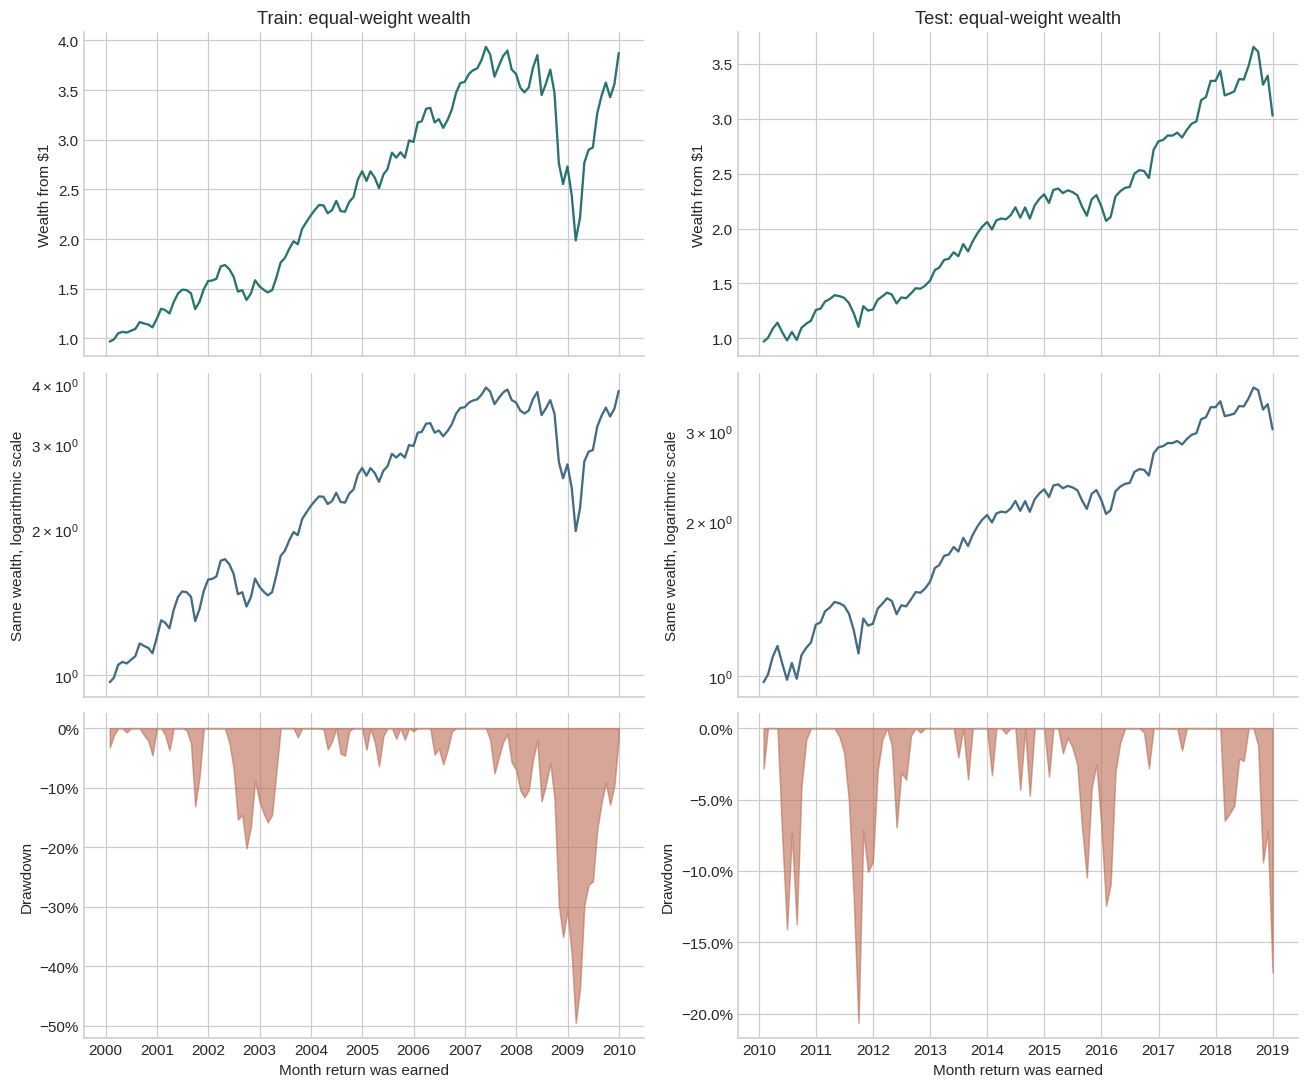

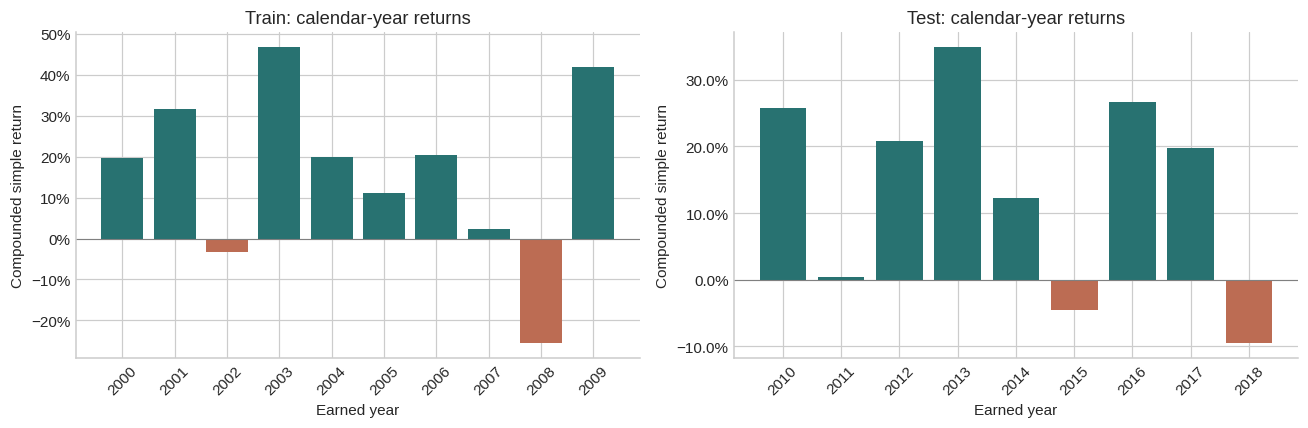

In [5]:
fig, axes = plt.subplots(3, 2, figsize=(12, 10), sharex='col')
for col, (split, book) in enumerate(books.items()):
    axes[0, col].plot(book.index, book.wealth, color='#287271')
    axes[0, col].set(title=f'{split.capitalize()}: equal-weight wealth', ylabel='Wealth from $1')
    axes[1, col].plot(book.index, book.wealth, color='#426b84')
    axes[1, col].set_yscale('log')
    axes[1, col].set(ylabel='Same wealth, logarithmic scale')
    axes[2, col].fill_between(book.index, book.drawdown.to_numpy(), 0, color='#bc6c53', alpha=0.6)
    axes[2, col].set(ylabel='Drawdown', xlabel='Month return was earned')
    axes[2, col].yaxis.set_major_formatter(PercentFormatter(1))
save_figure(fig, '05_equal_weight_growth_and_drawdown')

annual = {split: (1 + book.simple_return).groupby(book.index.year).prod() - 1 for split, book in books.items()}
annual_table = pd.concat(annual, names=['split', 'year']).rename('simple_return').to_frame()
annual_table.to_csv(OUT / 'equal_weight_calendar_years.csv')
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (split, yearly) in zip(axes, annual.items()):
    ax.bar(yearly.index.astype(str), yearly.values, color=np.where(yearly.values >= 0, '#287271', '#bc6c53'))
    ax.axhline(0, color='gray', lw=0.7)
    ax.set(title=f'{split.capitalize()}: calendar-year returns', ylabel='Compounded simple return', xlabel='Earned year')
    ax.tick_params(axis='x', rotation=45)
    ax.yaxis.set_major_formatter(PercentFormatter(1))
save_figure(fig, '06_equal_weight_calendar_years')

## 6. What goes wrong in common alternatives?

The table below deliberately calculates several different quantities. The
arithmetic mean times twelve can be a useful summary, but it is not compounded
annual return. Pooling stock-month rows also weights months by their stock count.
Averaging stock log returns is not the return of an equal-capital portfolio.
Dropping December 2009 removes January 2010 and changes the evaluation window.
The two correct compounding identities should agree to floating-point precision.

In [6]:
test = panels['test']
book = books['test']
r = book.simple_return
wrong_stock_log_monthly = test.assign(stock_log=np.log1p(test[TARGET])).groupby('date').stock_log.mean()
recipes = pd.Series({
    'Correct: product of portfolio gross returns, annualized': (1 + r).prod() ** (12 / len(r)) - 1,
    'Correct: exp(12 * mean(PORTFOLIO log return)) - 1': np.expm1(np.log1p(r).mean() * 12),
    'Different quantity: 12 * mean monthly simple return': r.mean() * 12,
    'Wrong CAGR recipe: 12 * mean of all stock-month rows': test[TARGET].mean() * 12,
    'Wrong portfolio: exp(12 * mean of STOCK log returns) - 1': np.expm1(wrong_stock_log_monthly.mean() * 12),
    'Different window: drop the January 2010 return': (1 + r.iloc[1:]).prod() ** (12 / (len(r) - 1)) - 1,
}, name='reported_number')
recipes.to_csv(OUT / 'benchmark_formula_comparison.csv')
display(recipes.map(lambda x: f'{x:.4%}').to_frame())

,reported_number
"Correct: product of portfolio gross returns, annualized",13.0964%
Correct: exp(12 * mean(PORTFOLIO log return)) - 1,13.0964%
Different quantity: 12 * mean monthly simple return,13.5711%
Wrong CAGR recipe: 12 * mean of all stock-month rows,13.7016%
Wrong portfolio: exp(12 * mean of STOCK log returns) - 1,7.0936%
Different window: drop the January 2010 return,13.5921%


## 7. Rebalancing creates trades even if target weights stay equal

Suppose two stocks start with equal weights and only one doubles. Before the
next rebalance their weights are 2/3 and 1/3. Restoring halves trades 1/6 of
portfolio capital one way. Comparing equal target weights to last month's equal
targets would incorrectly show zero turnover.

The pipeline uses previous weights after realized returns and includes entries
and exits from the changing universe. One-way turnover is half the sum of absolute
weight changes. The first observation is NaN because initial funding from cash
is a separate convention. The required gross benchmark subtracts no costs.

In [7]:
turnover_summary = pd.DataFrame({
    split: {
        'average_one_way_turnover_excluding_initial_entry': book.turnover_one_way.iloc[1:].mean(),
        'maximum_one_way_turnover_excluding_initial_entry': book.turnover_one_way.iloc[1:].max(),
    }
    for split, book in books.items()
}).T
turnover_summary.to_csv(OUT / 'equal_weight_turnover.csv')
display(turnover_summary.map(lambda x: f'{x:.2%}'))
assert np.isclose(toy_book.turnover_one_way.iloc[1], 1 / 6)
print('No trading costs or risk-free interest were silently inserted into the required benchmark.')

,average_one_way_turnover_excluding_initial_entry,maximum_one_way_turnover_excluding_initial_entry
train,4.12%,8.09%
test,2.89%,4.66%


No trading costs or risk-free interest were silently inserted into the required benchmark.


## 8. What is now established, and what remains open?

We have a reproducible monthly benchmark with checked calendar alignment,
independent dollar arithmetic, simple/log consistency, sample-volatility Sharpe,
and a drawdown calculation that includes initial capital. The source manifest
identifies the files used. The benchmark's test number follows from the stated
rule; comparison with the professor's reference still requires that reference.

The data contain unusually large supplied stock returns, no executable prices,
and no independently documented universe or corporate-action rules. Those limit
claims about implementation and data provenance. They are not reasons to quietly
alter the graded benchmark.

The next step can be a single transparent non-ML strategy using the same return
engine, then a simpler feature-selection exercise. See
[04_pipeline_guide.md](04_pipeline_guide.md) and [05_strategy_ideas.md](05_strategy_ideas.md).
The earlier Part 1 is preserved for comparison.